# Stats Overview
Recall we said that instances are sampled from the "universe of instances"

In stats, we say that a sample (of observations) comes from a population
* dataset = sample
* universe of instances = population

Example
* Population: all college students in the US
    * Expensive to collect data from in terms of time, resources, etc.
* Sample: students in CPSC 222
    * Inexpensive

Some more key stats terms
* Parameter: any measurable characteristc of a population
    * Example: $\mu$ population mean
* Statistic: any measureabkle characteristic of a sample
    * Example: $\overline{x}$ sample mean
* Descriptive stats: stats that organize and summarize data
    * Example: central tendency measures, data dispersion measures, etc.
* Inferential stats: stats that infer something above and beyond what is known from the data
    * Example: inferring something about the population based on a sample

### Central Tendency
Measures the middle value(s) of a data distribution
* (Arithmetic) mean (AKA average)
    * Sensitive to outliers
    * Should only apply it when you know your data is numeric
* Median: middle value in a (sorted) list of numbers
* Mode: most frequently occurring value(s)
* Mid-value: $\frac{min + max}{2}$

TASK: calculate these measures with `ser`

### Data Dispersion (Spread)
Meaures how spread out the data are
* Range: max - min
* Quantiles
* Variance & standard deviation

Quantiles: divided (sorted) data into roughly equal sized partitions
* 2 quantiles: 1 data point that divides data into 2 halves (AKA median)
* Quartiles: 3 data points the divide data into 4 quarters
* Percentiles: 99 data points that divide data into 100 groups/partitions
    * 25th percentile (AKA 1st quartile)
    * 50th percentile (AKA 2nd quartile AKA median)
    * 75th percentile (AKA 3rd quartile)
* IQR (interquartile range): 3rd quartile - 1st quartile

Boxplots show percentile information in a nice data viz

Variance: measures how spread out data are from the mean
* Low variance: data are close to the mean
* High variance: data are quite spread out from the mean

More commonly, people use standard deviation because standard deviation is in the same units as the mean
* Standard deviation is the square root of variance
$$\frac{\sum_{i=1}^{n}(x_i - \bar{x})^2}{n}$$

Narrow data: [8, 9, 10, 11, 12]
Mean: 10.0
Range: 4
Sample std: 1.5811388300841898

Wide data: [0, 5, 10, 15, 20]
Mean: 10.0
Range: 20
Sample std: 7.905694150420948



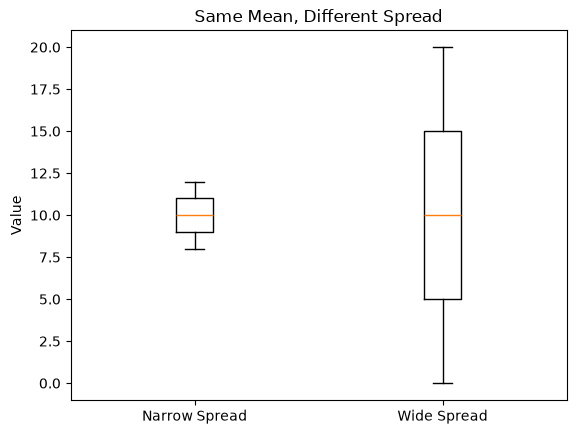

In [6]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Same mean, different spread
narrow = pd.Series([8, 9, 10, 11, 12])
wide = pd.Series([0, 5, 10, 15, 20])

for name, data in [("Narrow", narrow), ("Wide", wide)]:
    print(f"{name} data: {data.tolist()}")
    print("Mean:", data.mean())
    print("Range:", data.max() - data.min())
    print("Sample std:", data.std())
    print()

plt.boxplot([narrow, wide], tick_labels=["Narrow Spread", "Wide Spread"])
plt.ylabel("Value")
plt.title("Same Mean, Different Spread")
plt.show()

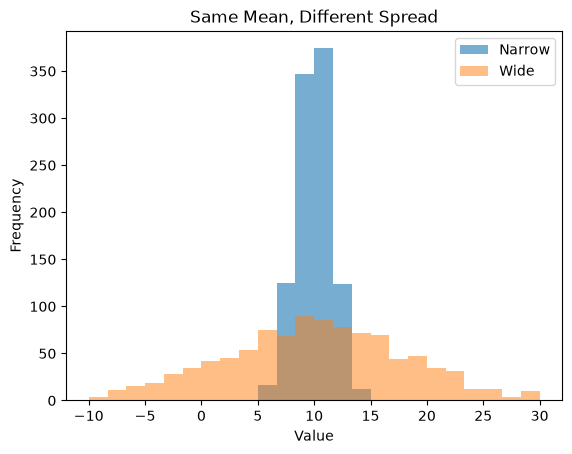

In [ ]:
rng = np.random.default_rng(42)

original_mean = narrow.mean()
narrow = rng.normal(original_mean, narrow.std(), 1000)
wide = rng.normal(original_mean, wide.std(), 1000)

# Make both sample means exactly 10
narrow += original_mean - narrow.mean()
wide += original_mean - wide.mean()

bins = np.linspace(-10, 30, 25)

plt.hist(narrow, bins=bins, alpha=0.6, label="Narrow")
plt.hist(wide, bins=bins, alpha=0.5, label="Wide")

plt.xlabel("Value")
plt.ylabel("Frequency")
plt.title("Same Mean, Different Spread")
plt.legend()
plt.show()